# import Library

In [3]:
!pip install lightgbm

     ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
     ------- -------------------------------- 0.3/1.4 MB 7.9 MB/s eta 0:00:01
     ------------------------- -------------- 0.9/1.4 MB 11.0 MB/s eta 0:00:01
     ---------------------------------------- 1.4/1.4 MB 12.4 MB/s eta 0:00:00



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix

import warnings
warnings.filterwarnings("ignore")

## import data

In [3]:
credit_card_data = pd.read_csv("credit_card_clean.csv")
credit_card_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,female,university,married,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,female,university,single,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,female,university,single,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,female,university,married,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,male,university,married,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,male,highschool,married,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,male,highschool,single,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,male,university,single,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,male,highschool,married,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


### Data understanding

In [7]:
credit_card_data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

In [8]:
credit_card_data.shape

(30000, 25)

In [9]:
credit_card_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX           object
EDUCATION     object
MARRIAGE      object
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

### Data preparation 

In [4]:
le = LabelEncoder()
credit_card_data["SEX"]= le.fit_transform(credit_card_data["SEX"])
credit_card_data["EDUCATION"]= le.fit_transform(credit_card_data["EDUCATION"])
credit_card_data["MARRIAGE"]= le.fit_transform(credit_card_data["MARRIAGE"])
credit_card_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,0,3,0,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,0,3,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,0,3,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,0,3,0,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,3,0,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,1,0,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,1,2,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,3,2,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,1,0,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [16]:
credit_card_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

### model building

In [5]:
X= credit_card_data.drop(labels = "DEFAULT", axis = 1 )
y= credit_card_data["DEFAULT"]

In [19]:
X.shape,y.shape

((30000, 24), (30000,))

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size =0.20,random_state=123,shuffle=True,stratify=y)

In [21]:
X_train.shape,y_train.shape

((24000, 24), (24000,))

In [22]:
X_test.shape,y_test.shape

((6000, 24), (6000,))

### model training

## training time analysis

In [7]:
adb_classifier= AdaBoostClassifier()
gb_classifier= GradientBoostingClassifier(n_estimators=50)
xgb_classifier = XGBClassifier(n_estimators=50)
lgbm_classifier = LGBMClassifier(n_estimators=50)

In [8]:
%%time
adb_classifier.fit(X_train,y_train)


CPU times: total: 4.52 s
Wall time: 5.22 s


,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [11]:
%%time
gb_classifier.fit(X_train,y_train)


CPU times: total: 12 s
Wall time: 12.9 s


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [13]:
%%time
xgb_classifier.fit(X_train,y_train)


CPU times: total: 1.05 s
Wall time: 671 ms


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [15]:
%%time
lgbm_classifier.fit(X_train,y_train)

[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.009032 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3514
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 24
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639
CPU times: total: 1.19 s
Wall time: 3.89 s


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,50
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


### model testing

In [38]:
y_predict_adb  = adb_classifier.predict(X_test)
y_predict_gb   =  gb_classifier.predict(X_test)
y_predict_xgb  =  xgb_classifier.predict(X_test)
y_predict_lgbm = lgbm_classifier.predict(X_test)

### model evaluation

### adaboosting

In [44]:
print("Confusion matrix:\n",(confusion_matrix(y_test,y_predict_adb)))
print("precision score:",round(precision_score(y_test,y_predict_adb),2))
print("recallscore:",round(recall_score(y_test,y_predict_adb),2))
print("accuracy score:",round(accuracy_score(y_test,y_predict_adb),2))

Confusion matrix:
 [[4487  186]
 [ 883  444]]
precision score: 0.7
recallscore: 0.33
accuracy score: 0.82


## gradient boosting

In [45]:
print("Confusion matrix:\n",(confusion_matrix(y_test,y_predict_gb)))
print("precision score:",round(precision_score(y_test,y_predict_gb),2))
print("recallscore:",round(recall_score(y_test,y_predict_gb),2))
print("accuracy score:",round(accuracy_score(y_test,y_predict_gb),2))

Confusion matrix:
 [[4463  210]
 [ 850  477]]
precision score: 0.69
recallscore: 0.36
accuracy score: 0.82


### xgb

In [46]:
print("Confusion matrix:\n",(confusion_matrix(y_test,y_predict_xgb)))
print("precision score:",round(precision_score(y_test,y_predict_xgb),2))
print("recallscore:",round(recall_score(y_test,y_predict_xgb),2))
print("accuracy score:",round(accuracy_score(y_test,y_predict_xgb),2))

Confusion matrix:
 [[4437  236]
 [ 848  479]]
precision score: 0.67
recallscore: 0.36
accuracy score: 0.82


### LGBM

In [47]:
print("Confusion matrix:\n",(confusion_matrix(y_test,y_predict_lgbm)))
print("precision score:",round(precision_score(y_test,y_predict_lgbm),2))
print("recallscore:",round(recall_score(y_test,y_predict_lgbm),2))
print("accuracy score:",round(accuracy_score(y_test,y_predict_lgbm),2))

Confusion matrix:
 [[4453  220]
 [ 837  490]]
precision score: 0.69
recallscore: 0.37
accuracy score: 0.82


# feature importance

In [9]:
adb_classifier.feature_importances_

array([0.        , 0.05726899, 0.        , 0.        , 0.01774711,
       0.        , 0.51398546, 0.03508031, 0.05249326, 0.00468648,
       0.01770951, 0.04232678, 0.01479643, 0.01535836, 0.        ,
       0.        , 0.01846551, 0.        , 0.0878239 , 0.0647271 ,
       0.03796819, 0.01956262, 0.        , 0.        ])

In [12]:
gb_classifier.feature_importances_

array([1.27040349e-02, 2.50365374e-02, 1.92716768e-03, 1.41640706e-03,
       2.63372932e-03, 2.90232463e-03, 6.50190722e-01, 9.30851199e-02,
       4.11214633e-02, 1.57455987e-02, 1.27534120e-02, 2.06182687e-02,
       2.17552157e-02, 4.69622847e-03, 3.07937606e-03, 3.51048596e-03,
       3.36262381e-04, 2.72972153e-03, 2.05667302e-02, 1.83422275e-02,
       2.23671901e-02, 1.01807466e-02, 3.96664039e-03, 8.33438916e-03])

In [14]:
xgb_classifier.feature_importances_

array([0.01490843, 0.02118965, 0.01449815, 0.01571108, 0.01426497,
       0.01414492, 0.43362716, 0.10911263, 0.05379299, 0.03646742,
       0.03635814, 0.03138818, 0.02092381, 0.01674494, 0.01786141,
       0.01256665, 0.01563221, 0.01493846, 0.01747491, 0.01944108,
       0.02296218, 0.01663779, 0.0129775 , 0.01637539], dtype=float32)

In [16]:
lgbm_classifier.feature_importances_

array([133, 107,  13,  29,  26,  77,  62,  36,  38,  23,  23,  32, 120,
        71,  53,  62,  54,  57,  75,  92,  90,  75,  61,  91], dtype=int32)

In [17]:
adb_feature_imp = adb_classifier.feature_importances_
gb_feature_imp= gb_classifier.feature_importances_
xgb_feature_imp = xgb_classifier.feature_importances_
lgbm_feature_imp = lgbm_classifier.feature_importances_

In [19]:
X.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object')

In [21]:
feature_importance_list = pd.DataFrame(data={"Feature":X.columns,
                  "Adaboost_feature":adb_feature_imp,
                  "GB_feature":gb_feature_imp,
                  "XGB_feature":xgb_feature_imp,
                  "LGBM_feature":lgbm_feature_imp})
feature_importance_list

,Feature,Adaboost_feature,GB_feature,XGB_feature,LGBM_feature
0,ID,0.000000,0.012704,0.014908,133
1,LIMIT_BAL,0.057269,0.025037,0.021190,107
2,SEX,0.000000,0.001927,0.014498,13
3,EDUCATION,0.000000,0.001416,0.015711,29
4,MARRIAGE,0.017747,0.002634,0.014265,26
5,AGE,0.000000,0.002902,0.014145,77
6,PAY_1,0.513985,0.650191,0.433627,62
7,PAY_2,0.035080,0.093085,0.109113,36
8,PAY_3,0.052493,0.041121,0.053793,38
9,PAY_4,0.004686,0.015746,0.036467,23


### Display top 10 feature of adaboost

In [22]:
import seaborn as sns

In [26]:
adaboost_top_feature= feature_importance_list.sort_values(by="Adaboost_feature",ascending=False)
adaboost_top_feature

,Feature,Adaboost_feature,GB_feature,XGB_feature,LGBM_feature
6,PAY_1,0.513985,0.650191,0.433627,62
18,PAY_AMT1,0.087824,0.020567,0.017475,75
19,PAY_AMT2,0.064727,0.018342,0.019441,92
1,LIMIT_BAL,0.057269,0.025037,0.021190,107
8,PAY_3,0.052493,0.041121,0.053793,38
11,PAY_6,0.042327,0.020618,0.031388,32
20,PAY_AMT3,0.037968,0.022367,0.022962,90
7,PAY_2,0.035080,0.093085,0.109113,36
21,PAY_AMT4,0.019563,0.010181,0.016638,75
16,BILL_AMT5,0.018466,0.000336,0.015632,54


<Axes: xlabel='Adaboost_feature', ylabel='Feature'>

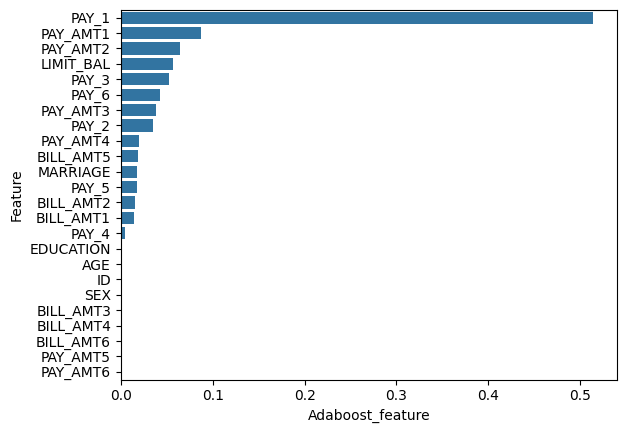

In [29]:
sns.barplot(data=adaboost_top_feature,y="Feature",x="Adaboost_feature")

<Axes: xlabel='GB_feature', ylabel='Feature'>

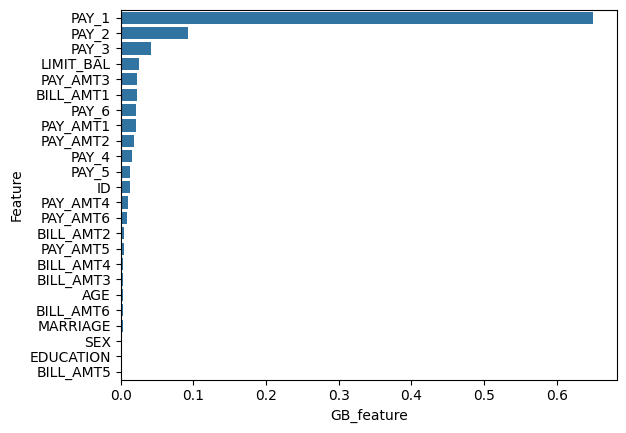

In [30]:
Gb_top_feature= feature_importance_list.sort_values(by="GB_feature",ascending=False)
Gb_top_feature
sns.barplot(data=Gb_top_feature,y="Feature",x="GB_feature")

In [33]:
Gb_top_feature= feature_importance_list.sort_values(by="GB_feature",ascending=False)
top_10_gb = Gb_top_feature.head(10)
top_10_gb

,Feature,Adaboost_feature,GB_feature,XGB_feature,LGBM_feature
6,PAY_1,0.513985,0.650191,0.433627,62
7,PAY_2,0.035080,0.093085,0.109113,36
8,PAY_3,0.052493,0.041121,0.053793,38
1,LIMIT_BAL,0.057269,0.025037,0.021190,107
20,PAY_AMT3,0.037968,0.022367,0.022962,90
12,BILL_AMT1,0.014796,0.021755,0.020924,120
11,PAY_6,0.042327,0.020618,0.031388,32
18,PAY_AMT1,0.087824,0.020567,0.017475,75
19,PAY_AMT2,0.064727,0.018342,0.019441,92
9,PAY_4,0.004686,0.015746,0.036467,23


<Axes: xlabel='GB_feature', ylabel='Feature'>

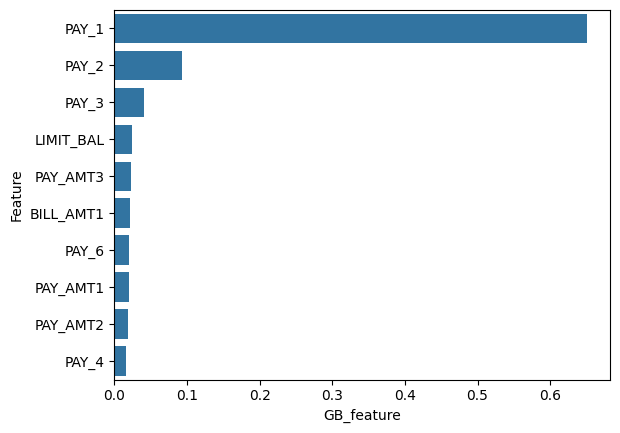

In [34]:
sns.barplot(data=top_10_gb,y="Feature",x="GB_feature")